# Chapter 17: Measurement Is a Model

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will place a decimal point by counting tenths, convert a side length before multiplying, see why a perimeter and an area answer different questions, and keep an exact result apart from its rounded display.

**A note before you start:** the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight down the page like a short chapter. If you are curious, peek at the code, and change a number to see what happens.

## Setup

This cell loads the tools for the calculations and the pictures. Nothing to change here.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, Wedge

INK, TEAL, TERRA, GREY, LIGHT = "#172a3b", "#2f7f79", "#a24a33", "#6b7785", "#d5dbe1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def say(label, text):
    """Print one labeled line of a worked calculation."""
    print(f"{label}: {text}")
from decimal import Decimal, ROUND_HALF_UP, ROUND_FLOOR

## 1. Find the whole-number product, then place the point

**Question:** where does the decimal point in $3.2 \times 1.8$ come from?

**The equation from the chapter:**

$$32\times18=32(10+8)=320+256=576$$

**What the symbols mean:**
- $3.2$ is 32 tenths, and $1.8$ is 18 tenths.
- The picture is a rectangle 32 tenths wide and 18 tenths tall, split into a tens piece ($10$) and an ones piece ($8$).
- Tenths times tenths gives hundredths, so the whole-number answer gets divided by 100.

**Predict first:** if the second factor were 2.5, what whole-number product would you expect, and where would the point go? (The table after the main example shows it.)

In [2]:
a, b = Decimal("3.2"), Decimal("1.8")
a_w, b_w = int(a * 10), int(b * 10)          # 32 and 18
tens, ones = (b_w // 10) * 10, b_w % 10      # 10 and 8
part_tens, part_ones = a_w * tens, a_w * ones
whole = part_tens + part_ones
product = Decimal(whole) / 100
say("Whole-number product", f"{a_w} x {b_w} = {part_tens} + {part_ones} = {whole}")
say("Split of the second factor", f"{a_w} x {b_w} = {a_w}({tens} + {ones}) = {a_w} x {tens} + {a_w} x {ones} = {part_tens} + {part_ones}")
say("Decimal product", f"{whole} / 100 = {product:.2f}")
low, high = a * 1, a * 2
say("Estimate band", f"between {low} and {high}")
say("Wrong placements", f"{product * 10:.1f} and {product / 10:.3f} fail the estimate")
print()
print("Other menu values:")
for f in ["1.8", "1.2", "1.5", "2.5"]:
    fb = Decimal(f); w = int(fb * 10)
    t, o = (w // 10) * 10, w % 10
    p = Decimal(32 * w) / 100
    print(f"  3.2 x {f}: 32 x {w} = {32*t} + {32*o} = {32*w}, then {32*w} / 100 = {p:.2f}")

Whole-number product: 32 x 18 = 320 + 256 = 576
Split of the second factor: 32 x 18 = 32(10 + 8) = 32 x 10 + 32 x 8 = 320 + 256
Decimal product: 576 / 100 = 5.76
Estimate band: between 3.2 and 6.4
Wrong placements: 57.6 and 0.576 fail the estimate

Other menu values:
  3.2 x 1.8: 32 x 18 = 320 + 256 = 576, then 576 / 100 = 5.76
  3.2 x 1.2: 32 x 12 = 320 + 64 = 384, then 384 / 100 = 3.84
  3.2 x 1.5: 32 x 15 = 320 + 160 = 480, then 480 / 100 = 4.80
  3.2 x 2.5: 32 x 25 = 640 + 160 = 800, then 800 / 100 = 8.00


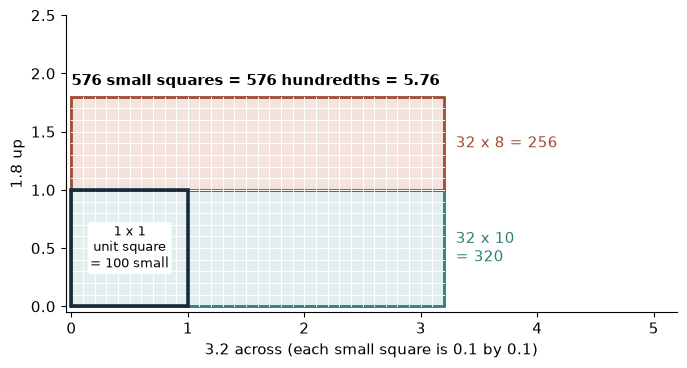

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.4))
W, H1, H2 = 3.2, tens / 10, ones / 10
ax.add_patch(Rectangle((0, 0), W, H1, facecolor="#e3efee", edgecolor=TEAL, linewidth=2))
ax.add_patch(Rectangle((0, H1), W, H2, facecolor="#f3e3dc", edgecolor=TERRA, linewidth=2))
for i in range(1, 32):
    ax.plot([i / 10] * 2, [0, H1 + H2], color="white", linewidth=0.7)
for j in range(1, b_w):
    ax.plot([0, W], [j / 10] * 2, color="white", linewidth=0.7)
ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, edgecolor=INK, linewidth=2.6, zorder=4))
ax.text(0.5, 0.5, "1 x 1\nunit square\n= 100 small", ha="center", va="center", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none"))
ax.text(W + 0.1, H1 / 2, f"32 x {tens}\n= {part_tens}", va="center", color=TEAL)
ax.text(W + 0.1, H1 + H2 / 2, f"32 x {ones} = {part_ones}", va="center", color=TERRA)
ax.text(0, H1 + H2 + 0.1, f"{whole} small squares = {whole} hundredths = {product:.2f}", fontweight="bold")
ax.set_xlim(-0.05, 5.2); ax.set_ylim(-0.05, 2.5); ax.set_aspect("equal")
ax.set_xlabel("3.2 across (each small square is 0.1 by 0.1)"); ax.set_ylabel("1.8 up")
plt.tight_layout(); plt.show()

**What this shows:** the product of the whole numbers is just counting small squares: 576 of them. Each small square is a hundredth of the bold unit square, so 576 hundredths is 5.76. The estimate (between 3.2 and 6.4) tells you right away that 57.6 and 0.576 cannot be right.

**Where it stops working:** this walkthrough has one decimal place in each factor. If a factor has two decimal places, you divide by ten once more; counting the places still works, but the count changes.

## 2. Convert a side first, then multiply

**Question:** a mat is 1.5 meters by 80 centimeters. Why do 1.20 and 12,000 both describe its area?

**The equation from the chapter:**

$$1\ \mathrm{m}^2=(100\ \mathrm{cm})(100\ \mathrm{cm})=10{,}000\ \mathrm{cm}^2.$$

**What the symbols mean:** m is meters, cm is centimeters, and $1\ \mathrm{m} = 100\ \mathrm{cm}$. The small raised 2 in $\mathrm{m}^2$ and $\mathrm{cm}^2$ means square meters and square centimeters. In the picture, each faint grid square is 10 cm by 10 cm.

**Predict first:** if the short side were 50 cm, would the area in square centimeters still be exactly 10,000 times the area in square meters?

In [4]:
length_m, width_cm = Decimal("1.5"), Decimal("80")
width_m = width_cm / 100
length_cm = length_m * 100
area_m2 = length_m * width_m
area_cm2 = length_cm * width_cm
perim = 2 * (length_m + width_m)
say("Second side in meters", f"{width_cm} / 100 = {width_m} m")
say("Area in square meters", f"{length_m} x {width_m} = {area_m2:.2f} m\u00b2")
say("Area in square centimeters", f"{length_cm:.0f} x {width_cm} = {area_cm2:,.0f} cm\u00b2")
say("Check", f"{area_cm2:,.0f} / 10,000 = {area_cm2 / 10000:.2f} m\u00b2")
say("Perimeter", f"2({length_m} + {width_m}) = {perim} m")
print()
print("Other menu values (short side, long side):")
for wc in ["80", "75", "50"]:
    for lm in ["1.5", "2"]:
        wm = Decimal(wc) / 100; L = Decimal(lm)
        print(f"  {wc} cm by {lm} m: {lm} x {wm} = {L*wm} m\u00b2, {L*100:.0f} x {wc} = {L*100*Decimal(wc):,.0f} cm\u00b2, perimeter {2*(L+wm)} m")

Second side in meters: 80 / 100 = 0.8 m
Area in square meters: 1.5 x 0.8 = 1.20 m²
Area in square centimeters: 150 x 80 = 12,000 cm²
Check: 12,000 / 10,000 = 1.20 m²
Perimeter: 2(1.5 + 0.8) = 4.6 m

Other menu values (short side, long side):
  80 cm by 1.5 m: 1.5 x 0.8 = 1.20 m², 150 x 80 = 12,000 cm², perimeter 4.6 m
  80 cm by 2 m: 2 x 0.8 = 1.6 m², 200 x 80 = 16,000 cm², perimeter 5.6 m
  75 cm by 1.5 m: 1.5 x 0.75 = 1.125 m², 150 x 75 = 11,250 cm², perimeter 4.50 m
  75 cm by 2 m: 2 x 0.75 = 1.50 m², 200 x 75 = 15,000 cm², perimeter 5.50 m
  50 cm by 1.5 m: 1.5 x 0.5 = 0.75 m², 150 x 50 = 7,500 cm², perimeter 4.0 m
  50 cm by 2 m: 2 x 0.5 = 1.0 m², 200 x 50 = 10,000 cm², perimeter 5.0 m


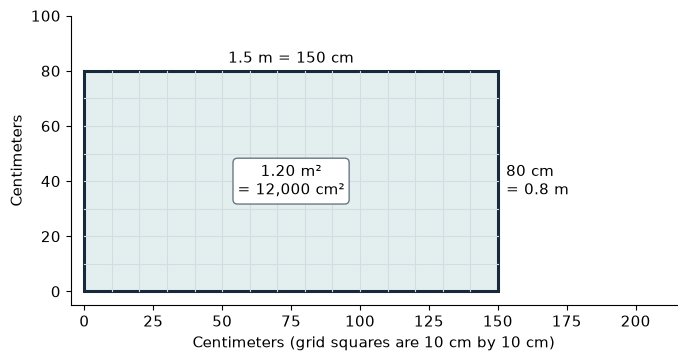

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
L, Wd = float(length_cm), float(width_cm)
ax.add_patch(Rectangle((0, 0), L, Wd, facecolor="#e3efee", edgecolor=INK, linewidth=2.2))
for x in range(10, int(L), 10):
    ax.plot([x, x], [0, Wd], color=LIGHT, linewidth=0.8)
for y in range(10, int(Wd), 10):
    ax.plot([0, L], [y, y], color=LIGHT, linewidth=0.8)
ax.text(L / 2, Wd + 3, f"{length_m} m = {L:.0f} cm", ha="center")
ax.text(L + 3, Wd / 2, f"{Wd:.0f} cm\n= {width_m} m", va="center")
ax.text(L / 2, Wd / 2, f"{area_m2:.2f} m\u00b2\n= {area_cm2:,.0f} cm\u00b2", ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=GREY))
ax.set_xlim(-5, 215); ax.set_ylim(-5, 100); ax.set_aspect("equal")
ax.set_xlabel("Centimeters (grid squares are 10 cm by 10 cm)"); ax.set_ylabel("Centimeters")
plt.tight_layout(); plt.show()

**What this shows:** convert each side once, then multiply. Because area multiplies two sides, the factor of 100 gets used twice, which is why one square meter holds 100 x 100 = 10,000 square centimeters.

**Where it stops working:** this is a flat rectangle with square corners. And a common slip: multiplying an area by 100 instead of 10,000 only converts one of its two directions, so the answer comes out wrong.

## 3. The boundary and the interior have different jobs

**Question:** can two rooms share the same perimeter and still have different areas?

**The equations from the chapter:**

$$A = lw \qquad\qquad P = 2l + 2w$$

**What the symbols mean:** $l$ is the length and $w$ is the width, both in meters. $A$ is the area in square meters (the interior). $P$ is the perimeter in meters (the boundary).

**Predict first:** every room in the table below has a 10.0 m boundary. Which one encloses the most floor?

In [6]:
l, w = Decimal("3.2"), Decimal("1.8")
say("Perimeter", f"2({l}) + 2({w}) = {2*l:.1f} + {2*w:.1f} = {2*l + 2*w:.1f} m")
say("Area", f"({l})({w}) = {l*w:.2f} m\u00b2")
say("Decomposition check", f"3.2 x 1 + 3.2 x 0.8 = 3.2 + 2.56 = {Decimal('3.2') + Decimal('2.56')}")
say("Units", "m x m = m\u00b2 for area; lengths added stay in m")
print()
print("Other rooms with the same 10.0 m boundary:")
for ls, ws in [("4.0", "1.0"), ("2.5", "2.5"), ("4.5", "0.5")]:
    L, Wd = Decimal(ls), Decimal(ws)
    print(f"  {ls} by {ws}: P = 2({ls}) + 2({ws}) = {2*L:.1f} + {2*Wd:.1f} = {2*L+2*Wd:.1f} m;  A = ({ls})({ws}) = {L*Wd:.2f} m\u00b2")

Perimeter: 2(3.2) + 2(1.8) = 6.4 + 3.6 = 10.0 m
Area: (3.2)(1.8) = 5.76 m²
Decomposition check: 3.2 x 1 + 3.2 x 0.8 = 3.2 + 2.56 = 5.76
Units: m x m = m² for area; lengths added stay in m

Other rooms with the same 10.0 m boundary:
  4.0 by 1.0: P = 2(4.0) + 2(1.0) = 8.0 + 2.0 = 10.0 m;  A = (4.0)(1.0) = 4.00 m²
  2.5 by 2.5: P = 2(2.5) + 2(2.5) = 5.0 + 5.0 = 10.0 m;  A = (2.5)(2.5) = 6.25 m²
  4.5 by 0.5: P = 2(4.5) + 2(0.5) = 9.0 + 1.0 = 10.0 m;  A = (4.5)(0.5) = 2.25 m²


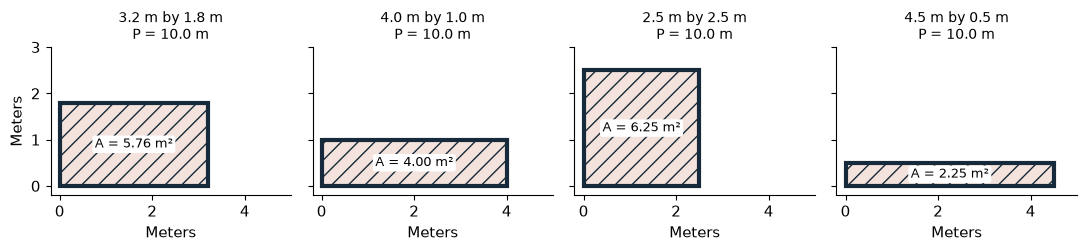

In [7]:
rooms = [("3.2", "1.8"), ("4.0", "1.0"), ("2.5", "2.5"), ("4.5", "0.5")]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for ax, (ls, ws) in zip(axes, rooms):
    L, Wd = float(ls), float(ws)
    ax.add_patch(Rectangle((0, 0), L, Wd, facecolor="#f3e3dc", edgecolor=INK, linewidth=3, hatch="//"))
    ax.text(L / 2, Wd / 2, f"A = {L*Wd:.2f} m\u00b2", ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none"))
    ax.set_title(f"{ls} m by {ws} m\nP = {2*L+2*Wd:.1f} m", fontsize=10)
    ax.set_xlim(-0.2, 5); ax.set_ylim(-0.2, 3); ax.set_aspect("equal")
    ax.set_xlabel("Meters")
axes[0].set_ylabel("Meters")
plt.tight_layout(); plt.show()

**What this shows:** the dark line is the boundary that $P$ adds up; the hatched region is the interior that $A$ counts. Reshaping a room keeps the boundary the same and moves the interior. Edging is bought by the meter of boundary; flooring is bought by the square meter of interior.

**Where it stops working:** the two numbers answer different questions, so 10.0 m and 5.76 m² cannot be ranked against each other. They have different units. The comparison also assumes a flat rectangle with perpendicular sides.

## 4. An exact result and its rounded display

**Question:** when 5.76 m² is shown as 5.8 m², what has changed and what has not?

**The equation from the chapter:**

$$5.76\ \text{m}^2 \approx 5.8\ \text{m}^2$$

**What the symbols mean:** 5.76 m² is the exact arithmetic on the stated inputs. The sign $\approx$ means the display is approximately equal to the calculated value.

**Predict first:** for 5.75, is it nearer 5.7 or 5.8? (Hint: it is exactly halfway, so a tie rule decides.)

In [8]:
from decimal import ROUND_HALF_UP, ROUND_FLOOR
v = Decimal("5.76")
below = v.quantize(Decimal("0.1"), rounding=ROUND_FLOOR)
above = below + Decimal("0.1")
shown = v.quantize(Decimal("0.1"), rounding=ROUND_HALF_UP)
say("Calculated (exact)", f"{v} m\u00b2")
say("Distances to neighbors", f"{v} - {below} = {v - below}; {above} - {v} = {above - v}")
say("Which is nearer", f"{above - v} is less than {v - below}, so {v} is nearer {shown}")
say("Nearest-tenth display", f"\u2248{shown} m\u00b2")
print()
print("Other menu values:")
for s in ["5.74", "5.75", "5.70"]:
    x = Decimal(s); b = x.quantize(Decimal("0.1"), rounding=ROUND_FLOOR); a = b + Decimal("0.1")
    note = " (exactly halfway, so the round-half-up rule gives the upper one)" if x - b == a - x else ""
    print(f"  {s}: {s} - {b} = {x-b}; {a} - {s} = {a-x}; display {x.quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)}{note}")

Calculated (exact): 5.76 m²
Distances to neighbors: 5.76 - 5.7 = 0.06; 5.8 - 5.76 = 0.04
Which is nearer: 0.04 is less than 0.06, so 5.76 is nearer 5.8
Nearest-tenth display: ≈5.8 m²

Other menu values:
  5.74: 5.74 - 5.7 = 0.04; 5.8 - 5.74 = 0.06; display 5.7
  5.75: 5.75 - 5.7 = 0.05; 5.8 - 5.75 = 0.05; display 5.8 (exactly halfway, so the round-half-up rule gives the upper one)
  5.70: 5.70 - 5.7 = 0.00; 5.8 - 5.70 = 0.10; display 5.7


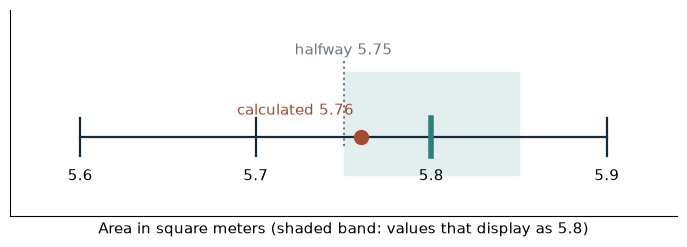

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.axvspan(5.75, 5.85, ymin=0.2, ymax=0.7, color="#e3efee")
ax.plot([5.6, 5.9], [0, 0], color=INK, linewidth=1.6)
for t in [5.6, 5.7, 5.8, 5.9]:
    hl = abs(t - float(shown)) < 1e-9
    ax.plot([t, t], [-0.12, 0.12], color=TEAL if hl else INK, linewidth=4 if hl else 1.6)
    ax.text(t, -0.2, f"{t}", ha="center", va="top")
ax.plot([5.75, 5.75], [-0.06, 0.5], color=GREY, linestyle="dotted")
ax.text(5.75, 0.52, "halfway 5.75", ha="center", color=GREY)
ax.plot([float(v)], [0], "o", color=TERRA, markersize=10)
ax.text(float(v) - 0.004, 0.14, "calculated 5.76", ha="right", color=TERRA)
ax.set_xlim(5.56, 5.94); ax.set_ylim(-0.5, 0.8); ax.set_yticks([]); ax.set_xticks([])
ax.set_xlabel("Area in square meters (shaded band: values that display as 5.8)")
plt.tight_layout(); plt.show()

**What this shows:** the display picks the nearer tenth on the number line. The calculated value does not move; only its presentation does. Keep the exact value for later work, and label the rounded one where it is shown.

**Where it stops working:** this is display rounding only. It says nothing about how a real length was measured or how precise the tape measure was. A value exactly halfway needs a stated tie rule.

## Practice

**1.** What is $2.4 \times 1.3$?

<details><summary>Show answer</summary>

Whole numbers first: $24 \times 13 = 24(10 + 3) = 240 + 72 = 312$.
Each factor has one decimal place, so divide by $10 \times 10 = 100$: $312 / 100 = 3.12$.
Estimate check: $2 < 2.4 < 3$ and $1 < 1.3 < 2$, so the answer should land between $2 \times 1 = 2$ and $3 \times 2 = 6$. 3.12 fits.

</details>

**2.** A rectangle is 2 m by 75 cm. What are its area and perimeter?

<details><summary>Show answer</summary>

Convert first: $75\ \text{cm} = 75 / 100 = 0.75\ \text{m}$.
Area: $2 \times 0.75 = 1.50\ \text{m}^2$. Check in centimeters: $200 \times 75 = 15{,}000\ \text{cm}^2$, and $15{,}000 / 10{,}000 = 1.50$.
Perimeter: $2(2 + 0.75) = 2(2.75) = 5.5\ \text{m}$.

</details>

**3.** What are the nearest-hundredth and nearest-tenth displays of $8.346\ \text{m}^2$?

<details><summary>Show answer</summary>

Hundredths: $8.346 - 8.34 = 0.006$ and $8.35 - 8.346 = 0.004$. The second is smaller, so the display is $\approx 8.35\ \text{m}^2$.
Tenths, starting from the original 8.346 (not from 8.35): $8.346 - 8.3 = 0.046$, which is less than $0.05$, so the display is $\approx 8.3\ \text{m}^2$.

</details>